In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("All machine learning libraries imported successfully!")

All machine learning libraries imported successfully!


In [15]:
df = pd.read_excel("../Data/Student_Depression_Dataset.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [16]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [17]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [18]:
display(df.describe())

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [19]:
print(df["Depression"].value_counts())

Depression
No     3263
Yes    1201
Name: count, dtype: int64


In [20]:
print(df["Depression"].value_counts(normalize=True) * 100)

Depression
No     73.095878
Yes    26.904122
Name: proportion, dtype: float64


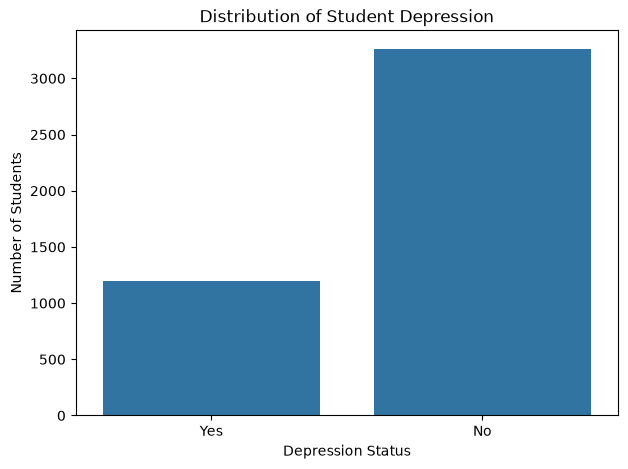

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Depression")

plt.title("Distribution of Student Depression")
plt.xlabel("Depression Status")
plt.ylabel("Number of Students")

plt.show()

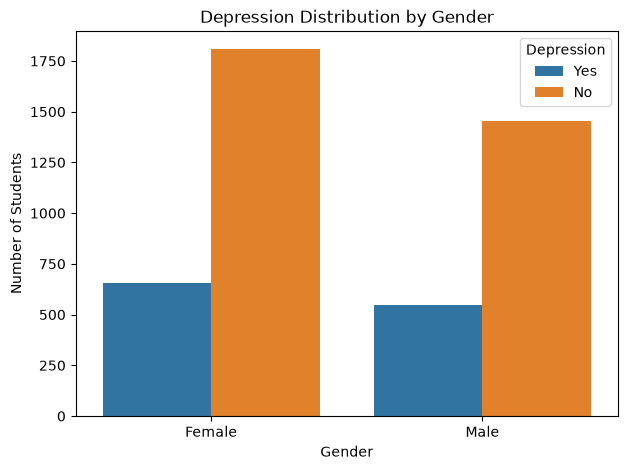

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender", hue="Depression")

plt.title("Depression Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.legend(title="Depression")

plt.show()

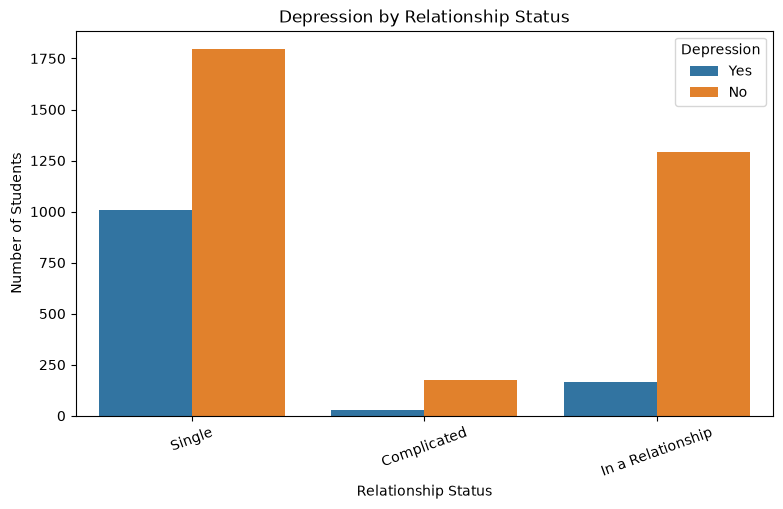

In [31]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Relationship_status", hue="Depression")

plt.title("Depression by Relationship Status")
plt.xlabel("Relationship Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)

plt.show()

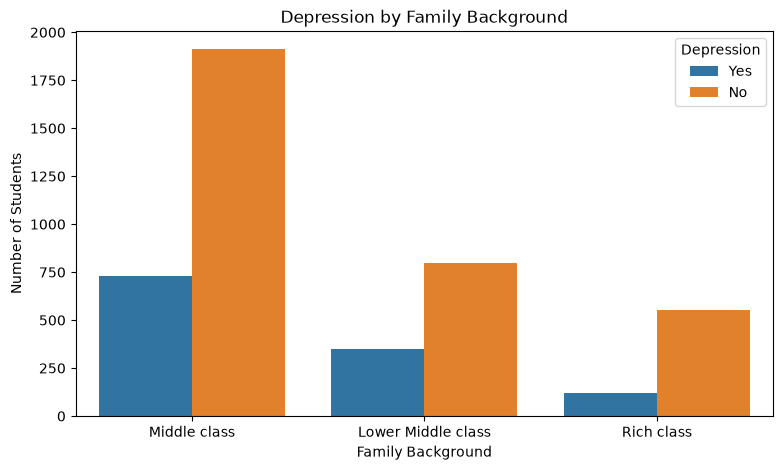

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Family_background", hue="Depression")

plt.title("Depression by Family Background")
plt.xlabel("Family Background")
plt.ylabel("Number of Students")

plt.show()

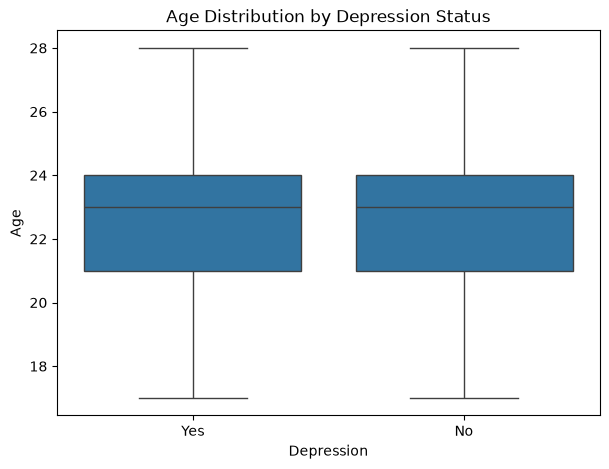

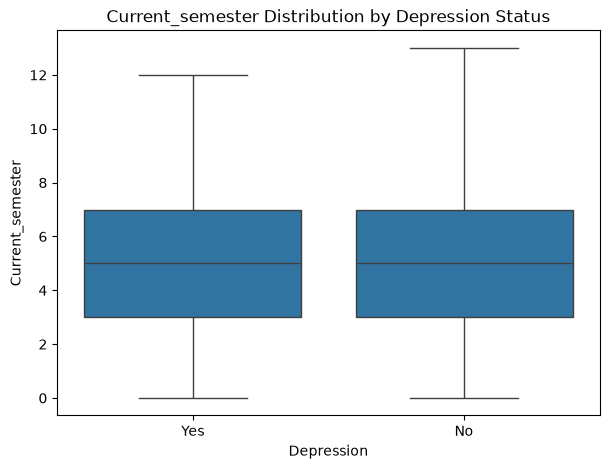

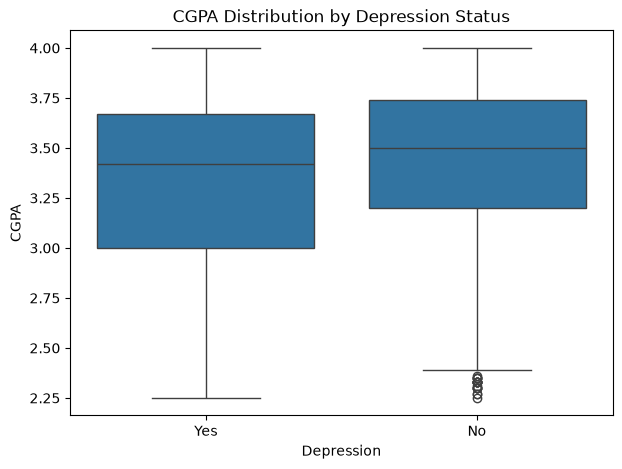

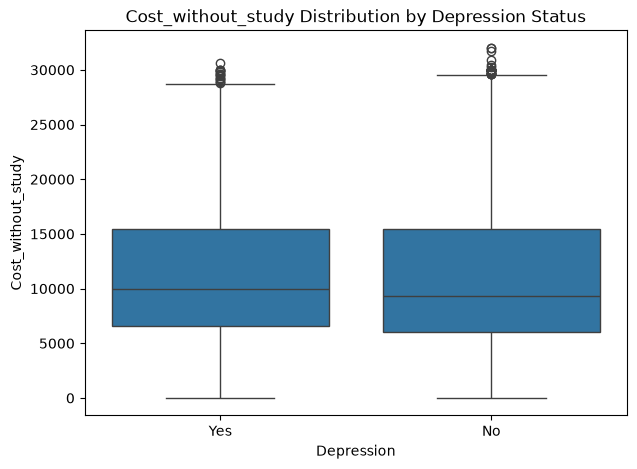

In [33]:
numerical_columns = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

for column in numerical_columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df, x="Depression", y=column)

    plt.title(f"{column} Distribution by Depression Status")
    plt.show()

In [34]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Health_condition",
    "Home_division"
]

for column in categorical_columns:
    print(f"\nDepression rate by {column}:")

    rates = pd.crosstab(
        df[column],
        df["Depression"],
        normalize="index"
    ) * 100

    display(rates.round(2))


Depression rate by Gender:


Depression,No,Yes
Gender,,
Female,73.40,26.60
Male,72.73,27.27



Depression rate by Family_background:


Depression,No,Yes
Family_background,,
Lower Middle class,69.42,30.58
Middle class,72.33,27.67
Rich class,82.41,17.59



Depression rate by Relationship_status:


Depression,No,Yes
Relationship_status,,
Complicated,86.76,13.24
In a Relationship,88.54,11.46
Single,64.07,35.93


... (6 outputs left out)


Depression rate by Health_condition:


Depression,No,Yes
Health_condition,,
Abnormal,45.06,54.94
Critical,0.00,100.00
Good,100.00,0.00
Normal,95.36,4.64



Depression rate by Home_division:


Depression,No,Yes
Home_division,,
Barisal,72.39,27.61
Chittagong,69.50,30.50
Dhaka,77.60,22.40
Khulna,68.98,31.02
Mymensingh,72.19,27.81
Rajshahi,68.44,31.56
Rangpur,68.04,31.96
Sylhet,76.40,23.60


In [38]:
features = df.drop("Depression", axis=1)

target = df["Depression"]
print("Features shape:", features.shape)
print("Target shape:", target.shape)

Features shape: (4464, 12)
Target shape: (4464,)


In [48]:
print(df["Depression"].unique())
print(df["Depression"].value_counts(dropna=False))
for value in df["Depression"].unique():
    print(repr(value))

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Depression
No     3263
Yes    1201
Name: count, dtype: int64
'Yes'
'No'


In [49]:
target = df["Depression"].map({
    "No": 0,
    "Yes": 1
})

print(target.value_counts())
print("Missing values:", target.isnull().sum())

Depression
0    3263
1    1201
Name: count, dtype: int64
Missing values: 0


In [50]:
from sklearn.model_selection import train_test_split

features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Training features:", features_train.shape)
print("Testing features:", features_test.shape)

print("Training target:", target_train.shape)
print("Testing target:", target_test.shape)

Training features: (3571, 12)
Testing features: (893, 12)
Training target: (3571,)
Testing target: (893,)


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


In [52]:
features_train_processed = preprocessor.fit_transform(features_train)

features_test_processed = preprocessor.transform(features_test)

print("Processed training data:", features_train_processed.shape)
print("Processed testing data:", features_test_processed.shape)

Processed training data: (3571, 31)
Processed testing data: (893, 31)


In [53]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [54]:
logistic_model.fit(
    features_train_processed,
    target_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [55]:
logistic_predictions = logistic_model.predict(
    features_test_processed
)

print(logistic_predictions[:20])

[0 0 0 1 1 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0]


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [58]:
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(target_test, logistic_predictions))

print("Precision:", precision_score(target_test, logistic_predictions))

print("Recall:", recall_score(target_test, logistic_predictions))

print("F1 Score:", f1_score(target_test, logistic_predictions))

Logistic Regression Results
Accuracy: 0.9686450167973124
Precision: 0.9274193548387096
Recall: 0.9583333333333334
F1 Score: 0.9426229508196722


In [59]:
print(classification_report(
    target_test,
    logistic_predictions,
    target_names=["No Depression", "Depression"]
))

               precision    recall  f1-score   support

No Depression       0.98      0.97      0.98       653
   Depression       0.93      0.96      0.94       240

     accuracy                           0.97       893
    macro avg       0.96      0.97      0.96       893
 weighted avg       0.97      0.97      0.97       893



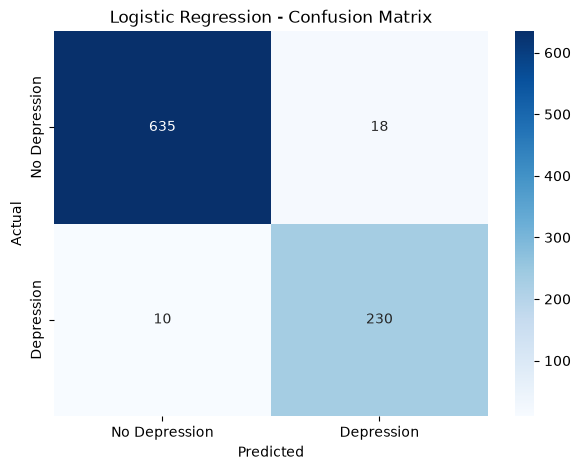

In [60]:
cm = confusion_matrix(target_test, logistic_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Depression", "Depression"],
    yticklabels=["No Depression", "Depression"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [62]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

In [63]:
decision_tree_model.fit(
    features_train_processed,
    target_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fea

In [64]:
decision_tree_predictions = decision_tree_model.predict(
    features_test_processed
)

print(decision_tree_predictions[:20])

[0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 1 0 0]


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Decision Tree Results")

print("Accuracy:", accuracy_score(target_test, decision_tree_predictions))

print("Precision:", precision_score(target_test, decision_tree_predictions))

print("Recall:", recall_score(target_test, decision_tree_predictions))

print("F1 Score:", f1_score(target_test, decision_tree_predictions))

Decision Tree Results
Accuracy: 0.9608062709966405
Precision: 0.8897338403041825
Recall: 0.975
F1 Score: 0.9304174950298211


In [67]:
print(classification_report(
    target_test,
    decision_tree_predictions,
    target_names=["No Depression", "Depression"]
))

               precision    recall  f1-score   support

No Depression       0.99      0.96      0.97       653
   Depression       0.89      0.97      0.93       240

     accuracy                           0.96       893
    macro avg       0.94      0.97      0.95       893
 weighted avg       0.96      0.96      0.96       893



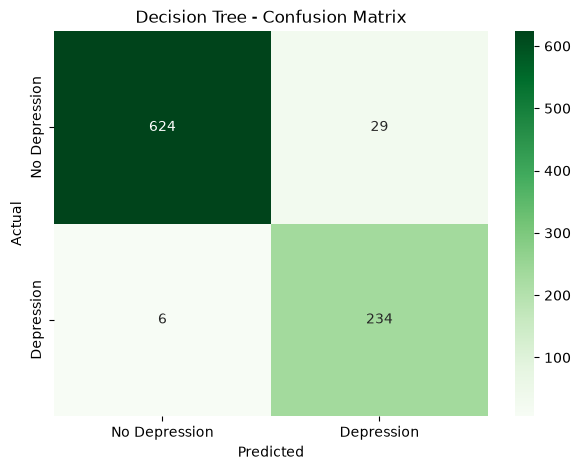

In [68]:
cm_tree = confusion_matrix(
    target_test,
    decision_tree_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Depression", "Depression"],
    yticklabels=["No Depression", "Depression"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

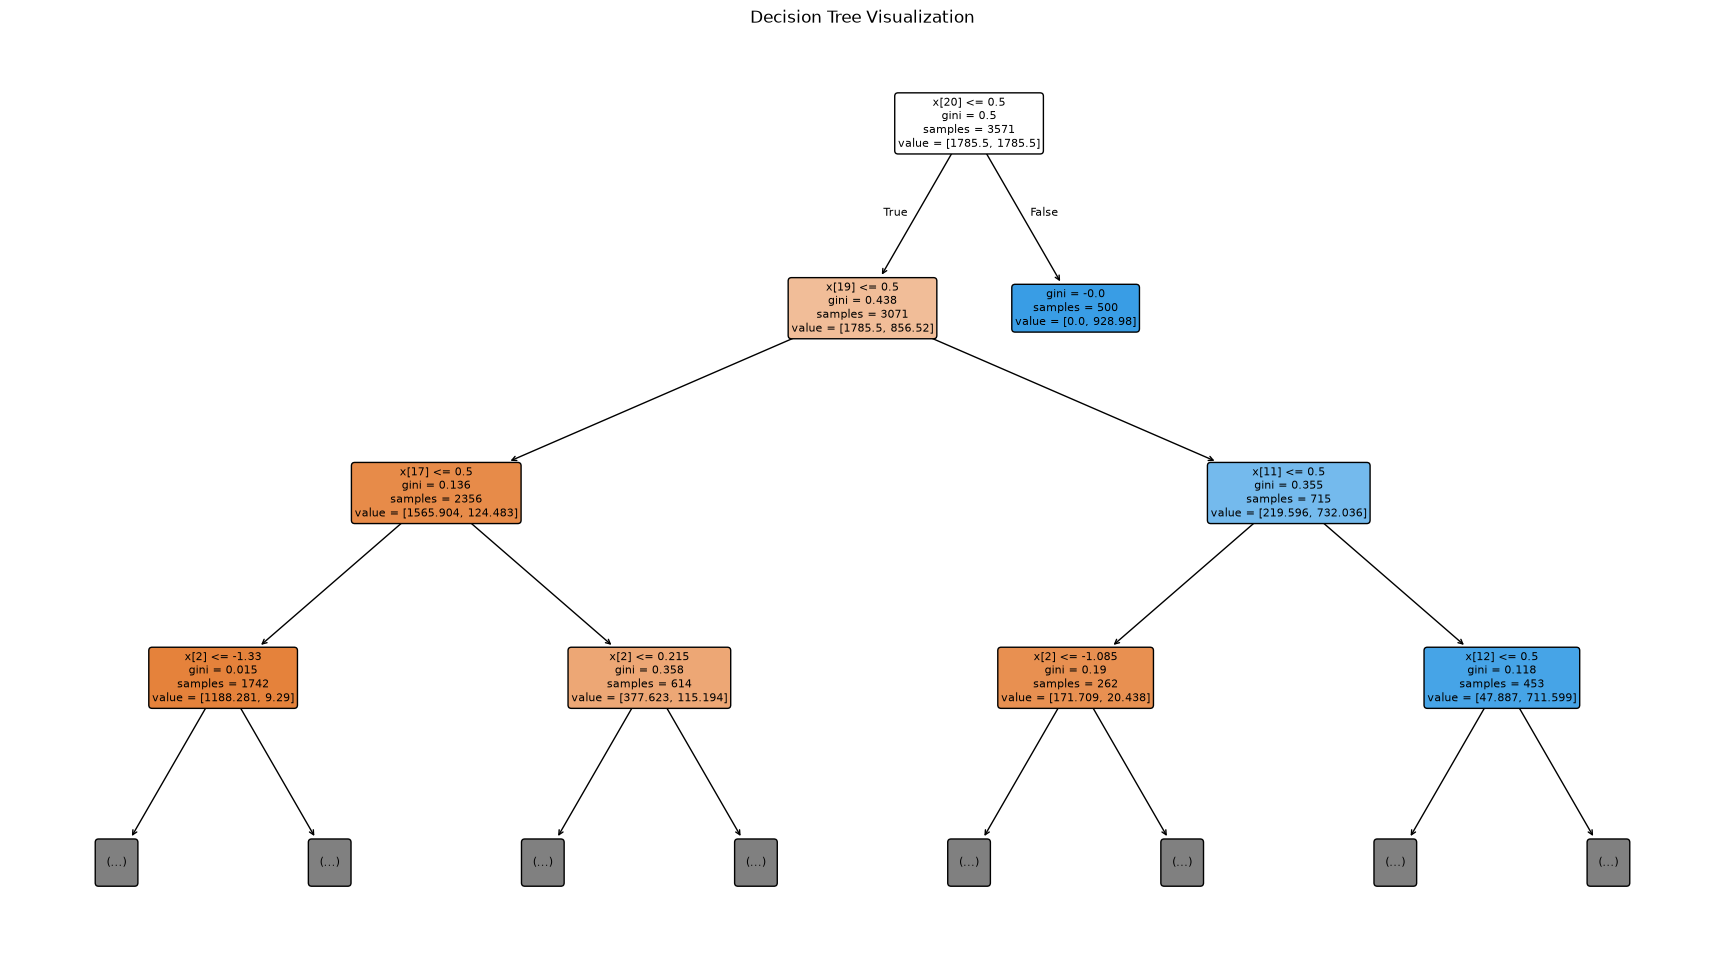

In [69]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))

plot_tree(
    decision_tree_model,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

In [70]:
from sklearn.ensemble import RandomForestClassifier

In [71]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [72]:
random_forest_model.fit(
    features_train_processed,
    target_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [73]:
random_forest_predictions = random_forest_model.predict(
    features_test_processed
)

print(random_forest_predictions[:20])

[0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 1 0 0]


In [74]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(
    target_test, random_forest_predictions
))

print("Precision:", precision_score(
    target_test, random_forest_predictions
))

print("Recall:", recall_score(
    target_test, random_forest_predictions
))

print("F1 Score:", f1_score(
    target_test, random_forest_predictions
))

Random Forest Results
Accuracy: 0.9888017917133258
Precision: 0.9914529914529915
Recall: 0.9666666666666667
F1 Score: 0.9789029535864979


In [75]:
print(classification_report(
    target_test,
    random_forest_predictions,
    target_names=["No Depression", "Depression"]
))

               precision    recall  f1-score   support

No Depression       0.99      1.00      0.99       653
   Depression       0.99      0.97      0.98       240

     accuracy                           0.99       893
    macro avg       0.99      0.98      0.99       893
 weighted avg       0.99      0.99      0.99       893



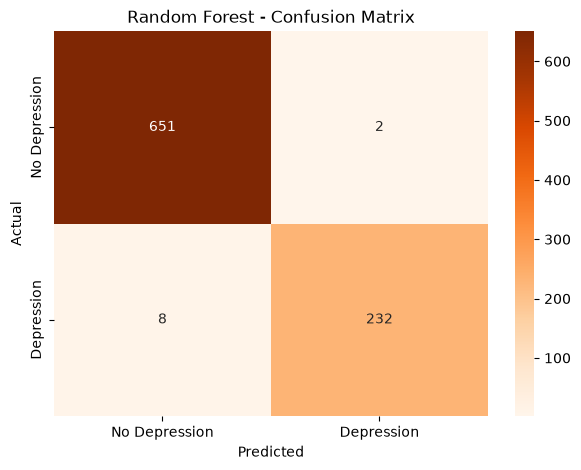

In [76]:
cm_rf = confusion_matrix(
    target_test,
    random_forest_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Depression", "Depression"],
    yticklabels=["No Depression", "Depression"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [78]:
logistic_probabilities = logistic_model.predict_proba(features_test_processed)[:, 1]

decision_tree_probabilities = decision_tree_model.predict_proba(features_test_processed)[:, 1]

random_forest_probabilities = random_forest_model.predict_proba(features_test_processed)[:, 1]

In [79]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(target_test, logistic_predictions),
        accuracy_score(target_test, decision_tree_predictions),
        accuracy_score(target_test, random_forest_predictions)
    ],
    "Precision": [
        precision_score(target_test, logistic_predictions),
        precision_score(target_test, decision_tree_predictions),
        precision_score(target_test, random_forest_predictions)
    ],
    "Recall": [
        recall_score(target_test, logistic_predictions),
        recall_score(target_test, decision_tree_predictions),
        recall_score(target_test, random_forest_predictions)
    ],
    "F1 Score": [
        f1_score(target_test, logistic_predictions),
        f1_score(target_test, decision_tree_predictions),
        f1_score(target_test, random_forest_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(target_test, logistic_probabilities),
        roc_auc_score(target_test, decision_tree_probabilities),
        roc_auc_score(target_test, random_forest_probabilities)
    ]
})

display(model_results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.969,0.927,0.958,0.943,0.993
1,Decision Tree,0.961,0.890,0.975,0.930,0.992
2,Random Forest,0.989,0.991,0.967,0.979,0.999


In [80]:
print(df.groupby("Depression")["Health_condition"].value_counts())

Depression  Health_condition
No          Normal              1704
            Good                1162
            Abnormal             397
Yes         Critical             634
            Abnormal             484
            Normal                83
Name: count, dtype: int64
